In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def lorentz(amplitude, center, fwhm, nu):
    half = (fwhm / 2)**2
    diff = (nu - center)**2
    return (amplitude * half) / (diff + half)

In [4]:
amplitude, center, fwhm = 200.0, 5.0, 1.0

nu = np.linspace(0, 10, 2000)
y = lorentz(amplitude, center, fwhm, nu)

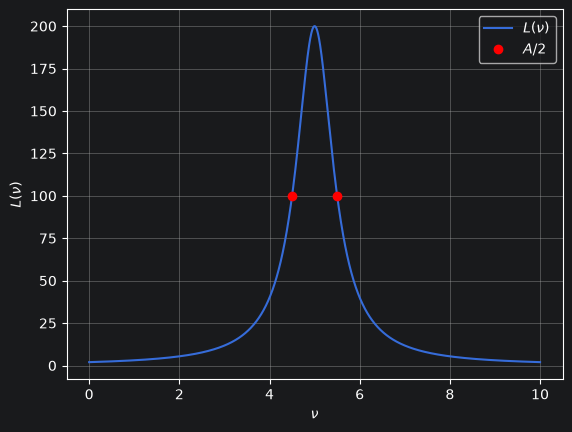

In [5]:
plt.plot(nu, y, label=r"$L(\nu)$")

x_half = center + np.array([-1, 1]) * fwhm / 2
y_half = lorentz(amplitude, center, fwhm, x_half)
plt.plot(x_half, y_half, "o", color="red", label=r"$A/2$")

plt.xlabel(r"$\nu$")
plt.ylabel(r"$L(\nu)$")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
def add_noise(rng, expected, sigma_read):
    poisson = rng.poisson(lam=expected, size=expected.shape)
    gauss = rng.normal(0, sigma_read, size=expected.shape)
    return poisson + gauss

In [7]:
y = add_noise(rng=np.random.default_rng(0), expected=y, sigma_read=3)

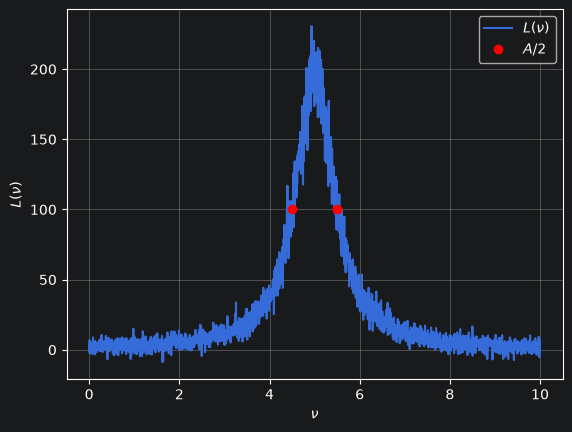

In [8]:
plt.plot(nu, y, label=r"$L(\nu)$")

x_half = center + np.array([-1, 1]) * fwhm / 2
y_half = lorentz(amplitude, center, fwhm, x_half)
plt.plot(x_half, y_half, "o", color="red", label=r"$A/2$")

plt.xlabel(r"$\nu$")
plt.ylabel(r"$L(\nu)$")
plt.legend()
plt.grid(True)
plt.show()

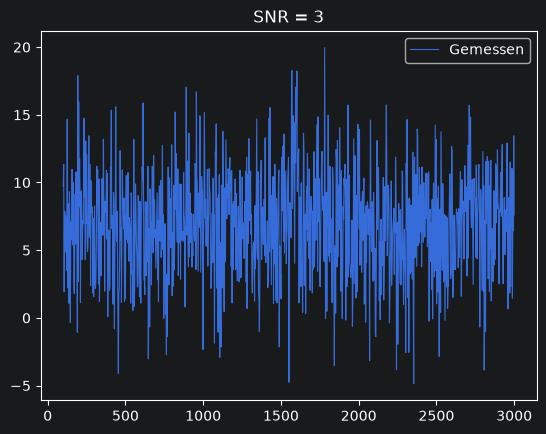

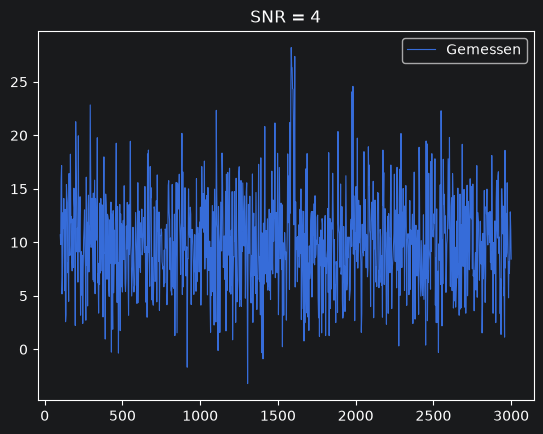

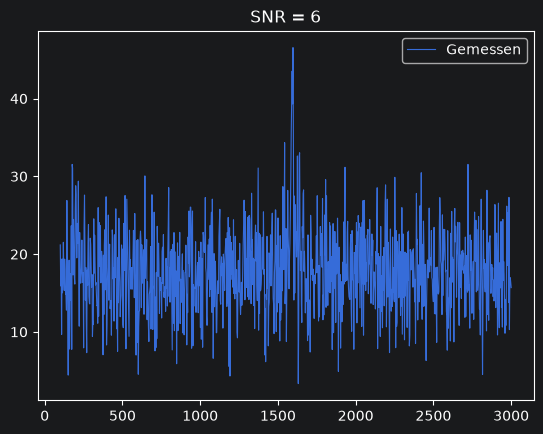

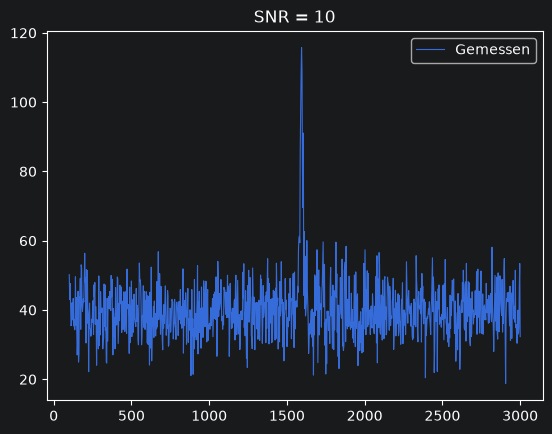

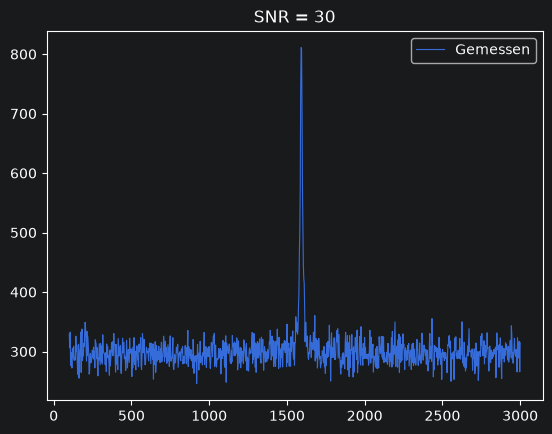

In [9]:
import src.raman_detection.generate as gen
import src.raman_detection.baseline as baseline

import yaml

with open("../config.yaml") as f:
    cfg = yaml.safe_load(f)

axis = cfg["axis"]
nu = np.linspace(axis["nu_min"], axis["nu_max"], axis["n_points"])

for snr in [3, 4, 6, 10, 30]:
    counts, meta = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(0), cfg=cfg, has_signal=True, snr=snr)
    plt.figure()
    plt.plot(nu, counts, lw=0.8, label="Gemessen")
    #plt.plot(nu, meta["expected"], lw=1.5, ls="--", label=r"Erwartungswert $\lambda$")
    plt.title(f"SNR = {snr}")
    plt.legend()
    plt.show()

In [10]:
from scipy.signal import savgol_filter

In [11]:
counts0, meta0 = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(1), cfg=cfg, has_signal=True, snr=3)
counts1, meta1 = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(4), cfg=cfg, has_signal=False, snr=3)
counts2, meta2 = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(2), cfg=cfg, has_signal=True, snr=3)
counts3, meta3 = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(12), cfg=cfg, has_signal=False, snr=3)
counts4, meta4 = gen.generate_spectrum(nu=nu, rng=np.random.default_rng(19), cfg=cfg, has_signal=True, snr=3)
counts = np.stack([counts0, counts1, counts2, counts3, counts4], axis=0)
meta = np.stack([meta0, meta1, meta2, meta3, meta4], axis=0)
smooth = savgol_filter(counts, window_length=11, polyorder=2)

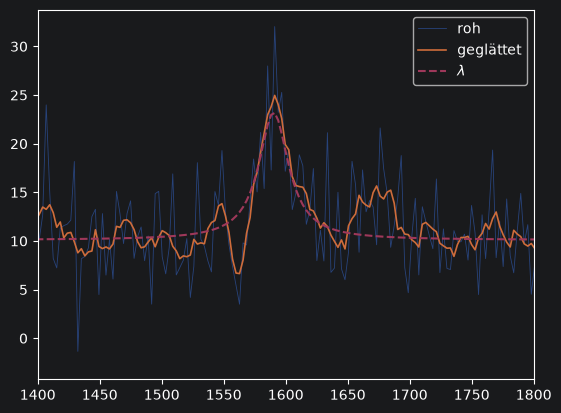

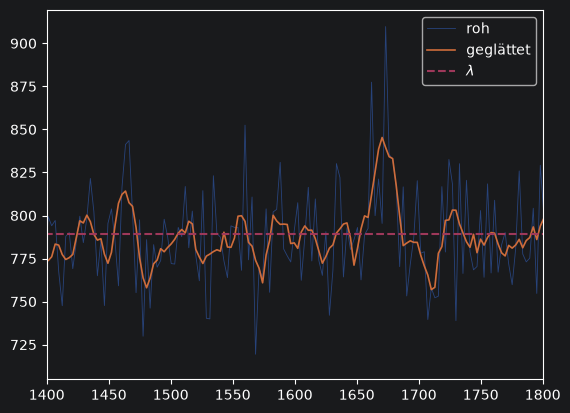

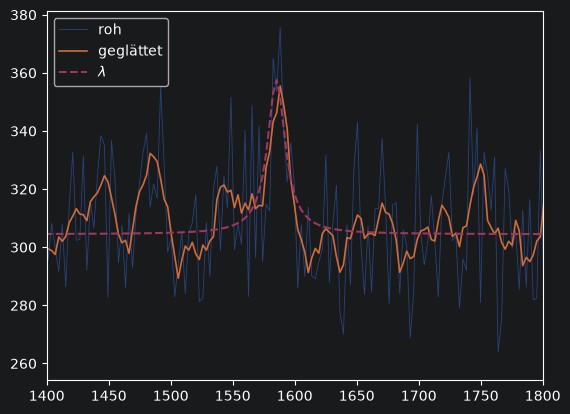

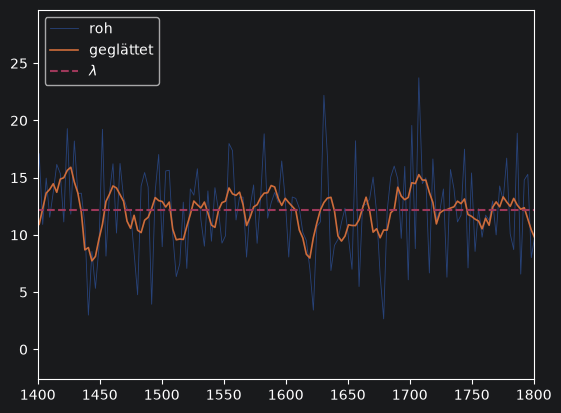

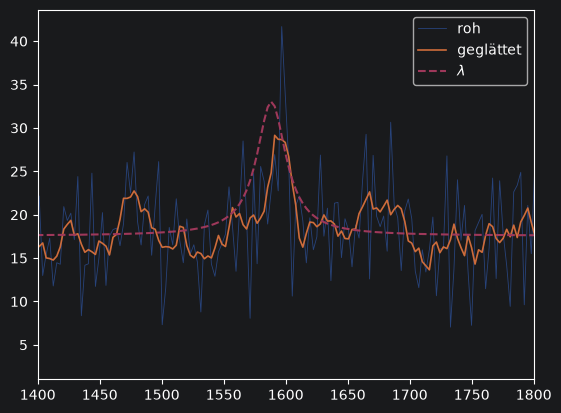

In [12]:
peaks = baseline.detection_statistic(X=counts, nu=nu, cfg=cfg)

for i in range(counts.shape[0]):
    plt.plot(nu, counts[i], lw=0.6, alpha=0.5, label="roh")
    plt.plot(nu, smooth[i], lw=1.2, label="geglättet")
    plt.plot(nu, meta[i]["expected"], ls="--", label=r"$\lambda$")
    plt.xlim(1400, 1800)
    plt.legend()
    plt.show()

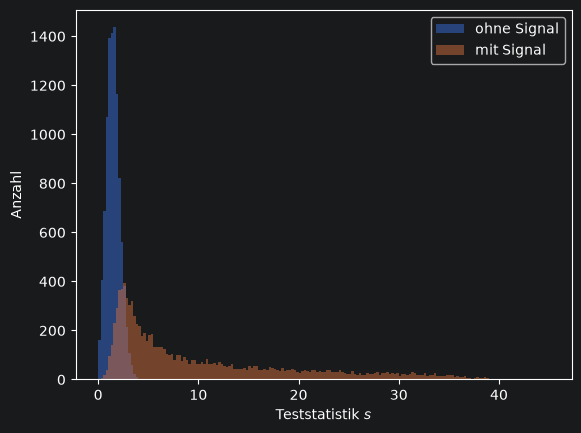

In [14]:
data = np.load("../data/dataset.npz")
X, y, snr, nu = data["X"], data["y"], data["snr"], data["nu"]

s = baseline.detection_statistic(X=X, nu=nu, cfg=cfg)

bins = np.linspace(0, 45, 181)
plt.hist(s[y == 0], bins=bins, alpha=0.5, label="ohne Signal")
plt.hist(s[y == 1], bins=bins, alpha=0.5, label="mit Signal")
plt.xlabel("Teststatistik $s$")
plt.ylabel("Anzahl")
plt.legend()
plt.show()

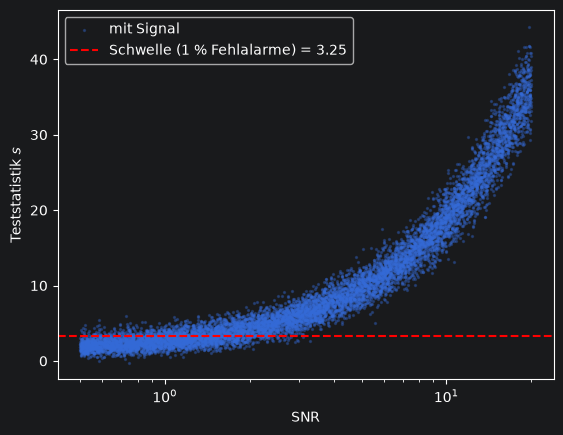

In [15]:
thr = np.quantile(s[y == 0], 0.99)

plt.scatter(snr[y == 1], s[y == 1], s=2, alpha=0.3, label="mit Signal")
plt.axhline(thr, color="red", ls="--", label=f"Schwelle (1 % Fehlalarme) = {thr:.2f}")
plt.xscale("log")
plt.xlabel("SNR")
plt.ylabel("Teststatistik $s$")
plt.legend()
plt.show()